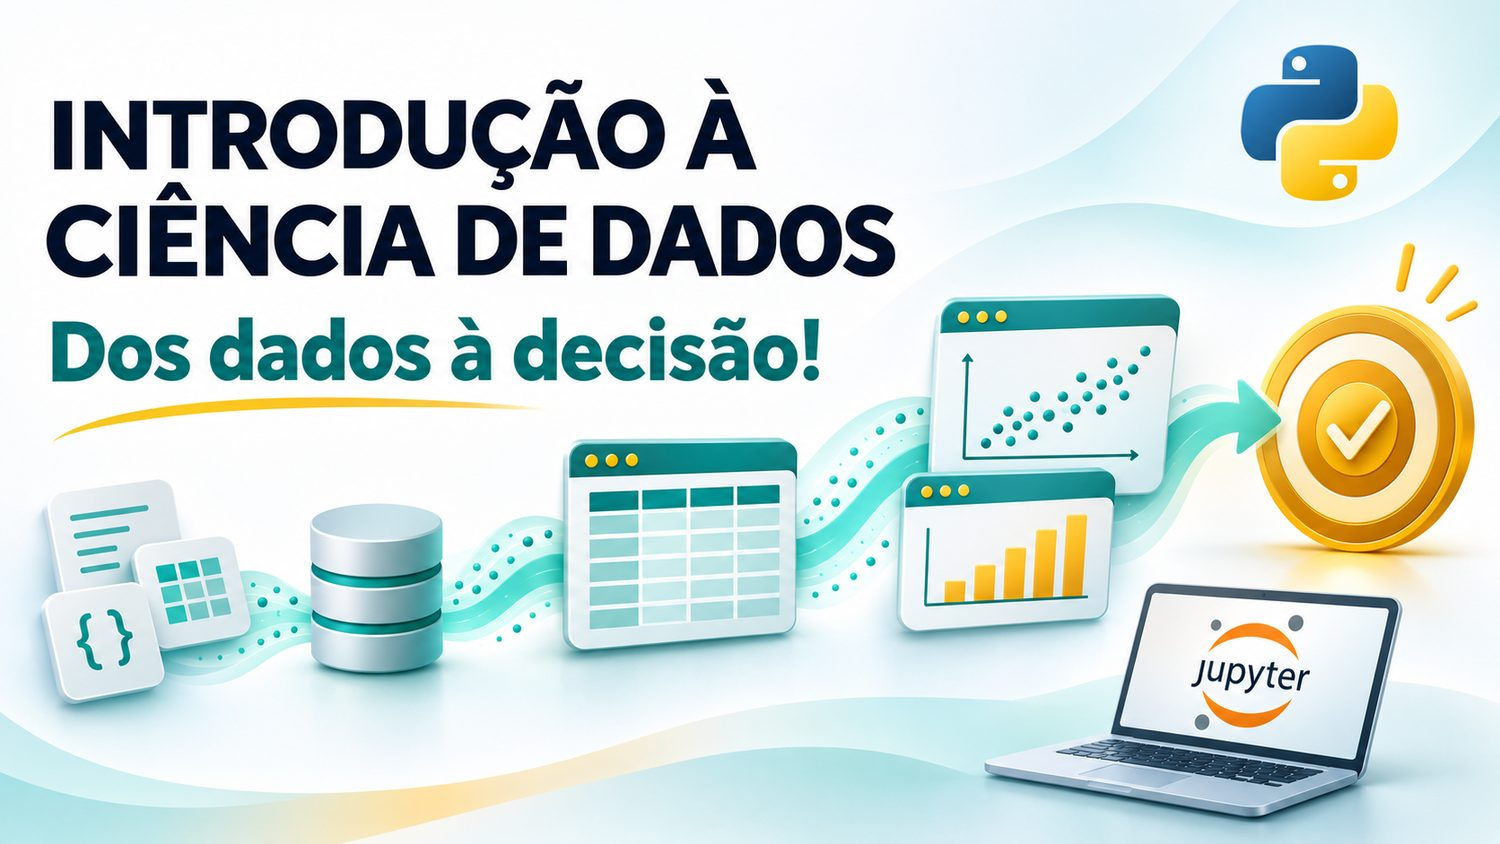

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/01_Do_Resultado_a_Mensagem.ipynb)

# Capítulo 1 – Do resultado à mensagem

Um modelo que ninguém percebe não muda nenhuma decisão. Os módulos anteriores acabaram todos com um «resumo para quem decide»; este módulo trata dessa última etapa como uma competência própria. Começamos pelo mais importante: transformar uma tabela de métricas numa **mensagem** que alguém fora da equipa consiga usar.

> **Objetivos:** distinguir um resultado de uma mensagem; identificar o leitor e a decisão antes de escrever; pôr a conclusão em primeiro lugar; traduzir métricas em consequências, com frequências naturais; escolher poucos números e dar-lhes um termo de comparação; estruturar um relatório de uma página; adaptar a mesma análise a leitores diferentes.

**Pré-requisitos:** os módulos 1 e 6. Este capítulo usa pouco código: o trabalho é sobretudo de escrita.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O caso deste módulo: quem vai desistir do curso?

Um centro de formação profissional tem cursos de nove meses. Cerca de um em cada cinco formandos desiste antes do fim. O centro tem uma equipa de acompanhamento (tutoria, apoio ao transporte, empréstimo de computadores), que só consegue seguir de perto uma parte dos formandos. A direção pediu um modelo que indique, no fim do primeiro mês, **quem está em maior risco de desistir**.

Os dados são sintéticos.

In [2]:
def gerar_formandos(n=6000, semente=97):
    """Gera formandos de um centro de formação profissional fictício (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    zona = rng.choice(["urbana", "rural"], n, p=[0.78, 0.22])
    rural = zona == "rural"
    idade = rng.normal(34, 10, n).clip(18, 62).round()
    escolaridade = rng.choice(["básico", "secundário", "superior"], n, p=[0.3, 0.5, 0.2])
    empregado = rng.random(n) < 0.45
    distancia = np.where(rural, rng.gamma(4.0, 6.0, n), rng.gamma(2.0, 2.5, n)).clip(0.5, 70).round(1)
    computador = rng.random(n) < np.where(rural, 0.62, 0.84)
    nota_inicial = (rng.normal(58, 15, n) + 6 * (escolaridade == "superior") - 5 * (escolaridade == "básico")).clip(5, 100).round()
    transporte_irregular = rural & (rng.random(n) < 0.30)                     # não fica registado em lado nenhum
    faltas = rng.poisson(np.clip(1.0 + 0.9 * empregado + 0.035 * distancia - 0.012 * (nota_inicial - 58) + 0.6 * ~computador, 0.15, None))
    z = (-2.95 + 0.42 * faltas + 0.55 * empregado - 0.022 * (nota_inicial - 58) + 0.55 * ~computador + 0.012 * distancia + 1.7 * transporte_irregular)
    desistiu = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"idade": idade, "zona": zona, "escolaridade": escolaridade, "empregado": empregado, "distancia_km": distancia,
                         "tem_computador": computador, "nota_inicial": nota_inicial, "faltas_primeiro_mes": faltas, "desistiu": desistiu})


formandos = gerar_formandos()
formandos.head()

,idade,zona,escolaridade,empregado,distancia_km,tem_computador,nota_inicial,faltas_primeiro_mes,desistiu
0,44.0,urbana,secundário,True,3.3,True,58.0,3,False
1,44.0,urbana,secundário,True,4.5,False,56.0,3,False
2,40.0,urbana,secundário,True,1.8,True,79.0,0,False
3,54.0,rural,básico,True,33.4,False,65.0,6,True
4,47.0,urbana,secundário,True,3.8,True,40.0,0,False


| Coluna | Significado |
| --- | --- |
| `idade` | Idade do formando |
| `zona` | Zona de residência: urbana ou rural |
| `escolaridade` | Básico, secundário ou superior |
| `empregado` | Se trabalha ao mesmo tempo que frequenta o curso |
| `distancia_km` | Distância de casa ao centro |
| `tem_computador` | Se tem computador em casa |
| `nota_inicial` | Nota no teste de diagnóstico, de 0 a 100 |
| `faltas_primeiro_mes` | Número de faltas no primeiro mês |
| `desistiu` | Se desistiu antes do fim do curso (o alvo) |

O modelo é uma regressão logística, com a preparação dos módulos 4 e 5. Não é o tema deste capítulo: interessa o que fazemos com o que ele devolve.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = ["idade", "distancia_km", "nota_inicial", "faltas_primeiro_mes", "empregado", "tem_computador"]
nominais = ["zona", "escolaridade"]
atributos = numericas + nominais
desenvolvimento, teste = train_test_split(formandos, test_size=0.3, random_state=0, stratify=formandos["desistiu"])
modelo = make_pipeline(ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(), nominais)]), LogisticRegression(max_iter=2000))
modelo.fit(desenvolvimento[atributos], desenvolvimento["desistiu"])
risco = modelo.predict_proba(teste[atributos])[:, 1]
real = teste["desistiu"].to_numpy()
print(f"{len(teste)} formandos de teste, {real.mean():.1%} desistiram")

1800 formandos de teste, 22.5% desistiram


## Um resultado não é uma mensagem

Eis o que um analista tem no ecrã no fim do trabalho.

In [4]:
from sklearn.metrics import classification_report, roc_auc_score

print(f"AUC = {roc_auc_score(real, risco):.3f}\n")
print(classification_report(real, risco >= 0.5, target_names=["ficou", "desistiu"], digits=3))

AUC = 0.760

              precision    recall  f1-score   support

       ficou      0.822     0.953     0.883      1395
    desistiu      0.641     0.291     0.401       405

    accuracy                          0.804      1800
   macro avg      0.732     0.622     0.642      1800
weighted avg      0.782     0.804     0.774      1800



Para quem fez o modelo, esta tabela diz muito. Para a diretora do centro, não diz nada: não sabe o que é *recall*, não sabe se 0,76 é bom, e sobretudo **não sabe o que fazer a seguir**.

Enviar-lhe esta tabela, com a frase «o modelo tem uma AUC de 0,76», é entregar um **resultado**. Uma **mensagem** responde à pergunta que ela fez.

| | Resultado | Mensagem |
| --- | --- | --- |
| Responde a | O que calculei? | O que deves saber, e fazer? |
| Linguagem | A da análise | A de quem lê |
| Números | Todos os que há | Os poucos que mudam a decisão |
| Ordem | A do trabalho: dados, método, resultados | A da decisão: conclusão, razões, reservas |
| Teste | Está certo? | Está certo, **e então?** |

O «e então?» é o teste mais útil: para cada frase e cada número do relatório, perguntar que diferença faz para quem lê. Se a resposta for «nenhuma», sai.

## Três perguntas antes de escrever

1. **Quem vai ler?** O que sabe do assunto, e de estatística? Quanto tempo tem?
2. **Que decisão vai tomar?** Que opções tem em cima da mesa?
3. **O que precisa de saber para decidir?** E em que é que poderia estar enganado se só lesse o título?

Para o nosso caso:

| Pergunta | Resposta |
| --- | --- |
| Quem lê | A diretora do centro e a coordenadora da equipa de acompanhamento. Conhecem bem os formandos; não têm formação em estatística. Vão ler numa reunião de meia hora |
| Que decisão | Se a equipa passa a escolher quem acompanha com a lista do modelo, em vez de esperar que os formadores sinalizem casos |
| O que precisam de saber | Quantos dos que desistem a lista apanha; quanto trabalho perdido dá; se é melhor do que o que fazem hoje; em quem o modelo falha |

A terceira linha é o **guião do relatório**. Repara que nenhum dos pontos é «a AUC».

## Traduzir métricas em consequências

A equipa de acompanhamento consegue seguir de perto **um em cada cinco** formandos. Essa restrição define o limiar: o que interessa é o que acontece se a equipa acompanhar o quinto de maior risco.

In [5]:
capacidade = 0.20
limiar = np.quantile(risco, 1 - capacidade)
acompanhado = risco >= limiar
vp, fp = int((acompanhado & real).sum()), int((acompanhado & ~real).sum())
fn, vn = int((~acompanhado & real).sum()), int((~acompanhado & ~real).sum())
print(f"Acompanhados: {acompanhado.sum()} de {len(real)} | sensibilidade {vp / (vp + fn):.1%} | precisão {vp / (vp + fp):.1%}")

Acompanhados: 360 de 1800 | sensibilidade 46.2% | precisão 51.9%


«Sensibilidade de 46%, precisão de 52%» está certo e continua a ser linguagem de analista. Há uma forma de dizer o mesmo que quase toda a gente compreende: **frequências naturais**. Em vez de percentagens de percentagens, contam-se pessoas num grupo de tamanho redondo.

In [6]:
por_100 = {nome: round(valor / len(real) * 100) for nome, valor in [("vp", vp), ("fp", fp), ("fn", fn), ("vn", vn)]}
print(f"Em cada 100 formandos, {por_100['vp'] + por_100['fn']} acabam por desistir.")
print(f"A equipa acompanha os {por_100['vp'] + por_100['fp']} que o modelo indica.")
print(f"  {por_100['vp']} deles iam mesmo desistir: são os que a equipa tem oportunidade de ajudar.")
print(f"  {por_100['fp']} não iam desistir: recebem um acompanhamento de que não precisavam.")
print(f"Ficam {por_100['fn']} formandos que desistem sem terem sido acompanhados.")

Em cada 100 formandos, 22 acabam por desistir.
A equipa acompanha os 20 que o modelo indica.
  10 deles iam mesmo desistir: são os que a equipa tem oportunidade de ajudar.
  10 não iam desistir: recebem um acompanhamento de que não precisavam.
Ficam 12 formandos que desistem sem terem sido acompanhados.


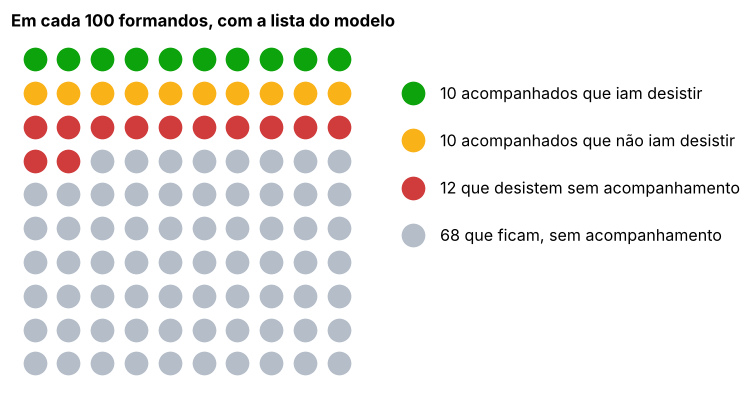

In [7]:
def grelha_de_pessoas(ax, contagens, titulo):
    """Desenha 100 pessoas numa grelha de 10 × 10, coloridas pelo que lhes acontece."""
    cores = [BOM] * contagens["vp"] + [AVISO] * contagens["fp"] + [MAU] * contagens["fn"]
    cores += [CINZA] * (100 - len(cores))
    for i, cor in enumerate(cores):
        ax.scatter(i % 10, 9 - i // 10, s=210, color=cor, marker="o")
    ax.set_xlim(-0.7, 9.7)
    ax.set_ylim(-0.7, 9.7)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo, fontsize=11)


fig, ax = plt.subplots(figsize=(8.6, 4.6))
grelha_de_pessoas(ax, por_100, "Em cada 100 formandos, com a lista do modelo")
legenda = [(BOM, f"{por_100['vp']} acompanhados que iam desistir"), (AVISO, f"{por_100['fp']} acompanhados que não iam desistir"),
           (MAU, f"{por_100['fn']} que desistem sem acompanhamento"), (CINZA, f"{100 - por_100['vp'] - por_100['fp'] - por_100['fn']} que ficam, sem acompanhamento")]
for i, (cor, texto) in enumerate(legenda):
    ax.scatter(11.2, 8 - i * 1.4, s=210, color=cor, clip_on=False)
    ax.text(12, 8 - i * 1.4, texto, va="center", fontsize=10.5)
ax.set_xlim(-0.7, 21)
plt.show()

Este desenho é a matriz de confusão do módulo 6, com as mesmas quatro células. A diferença é que mostra **pessoas**, e não taxas, e por isso deixa ver de imediato o que o modelo faz e o que não faz: apanha menos de metade dos que desistem, e cerca de metade do trabalho da equipa vai para quem não precisava.

### Dar um termo de comparação

«Apanha 10 em cada 22» é bom ou mau? Depende da alternativa. Um número sem comparação não informa.

In [8]:
ao_acaso = capacidade * real.mean() * 100
print(f"Acompanhando 20 formandos em cada 100, quantos dos que iam desistir se apanham?")
print(f"  escolhidos ao acaso:              {ao_acaso:.0f}")
print(f"  só pelas faltas do primeiro mês:  {(real[np.argsort(-teste['faltas_primeiro_mes'].to_numpy(), kind='stable')[:acompanhado.sum()]].sum() / len(real) * 100):.0f}")
print(f"  pela lista do modelo:             {por_100['vp']}")
print(f"  se o modelo fosse perfeito:       {min(20, round(real.mean() * 100))}")

Acompanhando 20 formandos em cada 100, quantos dos que iam desistir se apanham?
  escolhidos ao acaso:              5
  só pelas faltas do primeiro mês:  9
  pela lista do modelo:             10
  se o modelo fosse perfeito:       20


Com quatro linhas, a frase ganha sentido: a lista do modelo apanha o dobro dos casos de uma escolha ao acaso e fica a meio caminho do máximo possível. E apanha só **um caso a mais** do que a regra simples «acompanhar quem mais falta».

Esta última comparação é a mais honesta e a mais útil, porque é o que a equipa faria sem modelo. Mostra que quase todo o valor da lista vem das faltas, e que o resto do modelo acrescenta pouco. Esconder isto da direção seria vender o modelo por mais do que vale.

## Poucos números, bem escolhidos

| Regra | Em vez de | Escrever |
| --- | --- | --- |
| **Arredondar** ao que o leitor consegue reter | «a precisão é de 51,94%» | «cerca de metade» |
| **Contar pessoas**, e não taxas | «sensibilidade de 46%» | «apanha 10 dos 22 que desistem» |
| **Comparar** sempre | «apanha 10» | «apanha 10; ao acaso seriam 5» |
| **Dizer a unidade e o universo** | «melhora 5%» | «em cada 100 formandos, mais 1 caso apanhado» |
| **Um número por ideia** | uma tabela com doze métricas | os três números que respondem às três perguntas |
| **Distinguir pontos de percentagem** | «a taxa subiu 10%» (de 20% para 22%? para 30%?) | «subiu de 20% para 22%» |

O arredondamento não é falta de rigor. Com 1 800 formandos de teste, a precisão verdadeira pode estar alguns pontos acima ou abaixo de 52%; escrever «51,94%» sugere uma certeza que não existe. Voltamos a isto no capítulo 3.

## A conclusão primeiro

Um trabalho de análise faz-se numa ordem (dados, limpeza, modelo, resultados, conclusão) e **conta-se pela ordem inversa**. Quem lê quer saber primeiro onde se chegou; só depois, se tiver tempo e dúvidas, como.

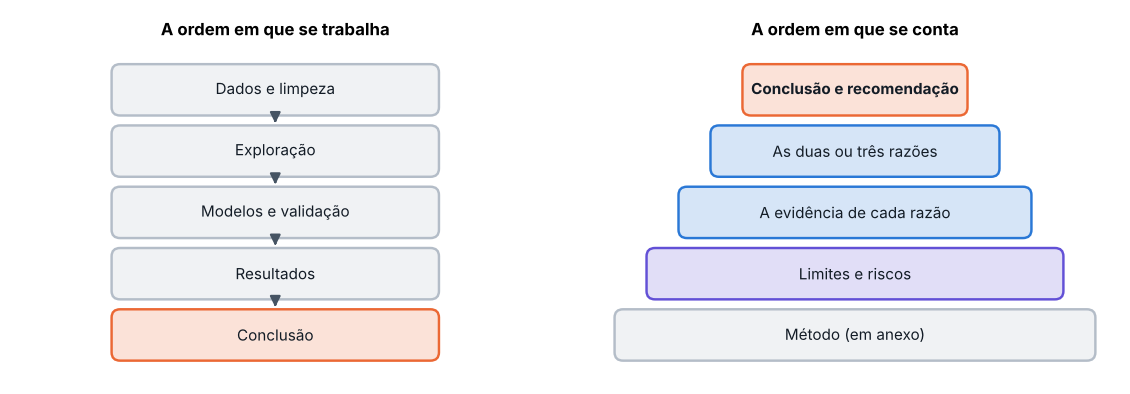

In [9]:
fig, ax = tela(13, 4.6, tamanho=(13, 4.4))
ax.text(3.1, 4.3, "A ordem em que se trabalha", ha="center", fontsize=11, fontweight="bold")
ax.text(9.9, 4.3, "A ordem em que se conta", ha="center", fontsize=11, fontweight="bold")
trabalho = ["Dados e limpeza", "Exploração", "Modelos e validação", "Resultados", "Conclusão"]
conto = [("Conclusão e recomendação", LARANJA), ("As duas ou três razões", AZUL), ("A evidência de cada razão", AZUL), ("Limites e riscos", VIOLETA), ("Método (em anexo)", CINZA)]
for i, texto in enumerate(trabalho):
    caixa(ax, 1.2, 3.35 - i * 0.74, 3.8, 0.58, texto, cor=LARANJA if i == 4 else CINZA, tamanho=10)
    if i < 4:
        seta(ax, (3.1, 3.33 - i * 0.74), (3.1, 3.2 - i * 0.74))
for i, (texto, cor) in enumerate(conto):
    largura = 2.6 + i * 0.75
    caixa(ax, 9.9 - largura / 2, 3.35 - i * 0.74, largura, 0.58, texto, cor=cor, tamanho=10, negrito=i == 0)
ax.set_ylim(0.1, 4.6)
plt.show()

À direita, uma pirâmide: no topo, uma frase; por baixo, o que a sustenta; na base, o pormenor para quem o quiser. Quem só ler a primeira linha fica com o essencial. Quem ler tudo encontra a justificação pela ordem em que as dúvidas aparecem.

### Um título que é uma frase

O título é a parte do relatório que toda a gente lê. Deve **dizer a conclusão**, e não o tema.

| Título-tema | Título-mensagem |
| --- | --- |
| Análise do abandono escolar | Uma lista de risco apanha quase metade das desistências, o dobro de uma escolha ao acaso |
| Resultados do modelo preditivo | Recomendamos testar a lista de risco num trimestre, em paralelo com a sinalização dos formadores |
| Importância das variáveis | As faltas do primeiro mês são o melhor sinal de que um formando vai desistir |

## O relatório de uma página

| Parte | Conteúdo | Tamanho |
| --- | --- | --- |
| **Título** | A conclusão, numa frase | 1 linha |
| **Recomendação** | O que se propõe fazer, e a decisão que se pede | 2 ou 3 linhas |
| **Porquê** | Duas ou três razões, cada uma com o seu número e a sua comparação | 1 parágrafo ou 3 pontos |
| **Uma figura** | A que mostra a razão principal | meia página, no máximo |
| **Limites** | O que o trabalho não garante, e o que pode correr mal | 2 ou 3 linhas |
| **Próximo passo** | Quem faz o quê, até quando | 1 ou 2 linhas |

O método, os dados e as métricas completas vão para um anexo ou para a ficha do modelo (capítulo 4).

Aplicado ao nosso caso:

> **Uma lista de risco no fim do primeiro mês apanha quase metade das desistências, o dobro de uma escolha ao acaso**
>
> **Recomendação.** Propomos que, no próximo trimestre, a equipa de acompanhamento escolha os formandos a seguir pela lista de risco, mantendo a sinalização pelos formadores. Pedimos autorização para esse ensaio.
>
> **Porquê.** Em cada 100 formandos, 22 desistem. Acompanhando os 20 que a lista indica, a equipa chega a 10 deles; escolhendo ao acaso chegaria a 5. Metade dos formandos da lista não iria desistir: é o custo de agir antes de os sinais serem evidentes. A lista vale sobretudo pelas faltas do primeiro mês: escolher simplesmente os 20 que mais faltaram apanharia 9.
>
> **Limites.** A lista não apanha 12 das 22 desistências, que não dão sinais no primeiro mês. O modelo indica quem está em risco, e não se o acompanhamento evita a desistência: isso só o ensaio dirá. Foi construído com dados de anos anteriores e pode falhar se o perfil dos formandos mudar.
>
> **Próximo passo.** A equipa de dados entrega a primeira lista na primeira semana do segundo mês. No fim do trimestre comparamos as desistências entre acompanhados e não acompanhados.

Nenhuma palavra do vocabulário técnico, meia dúzia de números, uma decisão pedida, e a comparação menos favorável ao modelo dita às claras. Tudo o que aqui está sai dos cálculos deste capítulo.

## O mesmo trabalho, três leitores

| | Direção | Equipa de acompanhamento | Equipa de dados |
| --- | --- | --- | --- |
| Quer saber | Vale a pena? Que riscos tem? | Quem está na lista, e porquê? O que faço com ela? | Como foi feito? Posso reproduzir e melhorar? |
| Formato | Uma página | A lista, com o motivo de cada caso | Notebook, ficha do modelo, código |
| Números | Três ou quatro, em pessoas | Por formando: o risco e os sinais | Todas as métricas, com incerteza |
| Linguagem | Do negócio | Da prática diária | Técnica |
| O erro típico | Dar-lhe o notebook | Dar-lhe só uma probabilidade | Dar-lhe só o resumo |

Para a equipa de acompanhamento, a probabilidade sozinha serve de pouco. O que ajuda é o **motivo**: «cinco faltas no primeiro mês, trabalha ao mesmo tempo, não tem computador». Com um modelo linear, esses motivos saem diretamente dos coeficientes (módulo 5).

In [10]:
nomes = modelo[0].get_feature_names_out()
contribuicoes = pd.DataFrame(modelo[0].transform(teste[atributos]) * modelo[-1].coef_[0], columns=[n.split("__")[1] for n in nomes], index=teste.index)
caso = teste.index[int(np.argsort(-risco)[3])]
print(f"Formando {caso}: risco estimado de {risco[teste.index.get_loc(caso)]:.0%}")
print(teste.loc[caso, atributos].to_string())
print("\nO que mais faz subir o risco deste formando:")
print(contribuicoes.loc[caso].sort_values(ascending=False).head(3).round(2).to_string())

Formando 3996: risco estimado de 89%
idade                    31.0
distancia_km             59.5
nota_inicial             49.0
faltas_primeiro_mes         8
empregado                True
tem_computador           True
zona                    rural
escolaridade           básico

O que mais faz subir o risco deste formando:
faltas_primeiro_mes    2.43
distancia_km           0.49
empregado              0.31


As três linhas finais são o que a tutora precisa de ver ao lado do nome. Dizem-lhe por onde começar a conversa.

## Palavras que convém traduzir

| Termo técnico | Em linguagem corrente |
| --- | --- |
| Sensibilidade | «Dos que desistem, quantos apanhamos» |
| Precisão | «Dos que assinalamos, quantos desistem mesmo» |
| Falso positivo | «Um formando acompanhado sem precisar» |
| Falso negativo | «Uma desistência que não vimos chegar» |
| Limiar | «A partir de que nível de risco agimos» |
| Linha de base | «O que conseguiríamos sem modelo» |
| Conjunto de teste | «Formandos que o modelo nunca tinha visto» |
| Sobreajuste | «O modelo decorou os casos antigos em vez de aprender a regra» |
| Correlação, associação | «Andam juntos; não sabemos se um causa o outro» |
| Estatisticamente significativo | «Dificilmente se explica só pelo acaso» (e dizer o tamanho do efeito) |

Traduzir não é simplificar de mais. A frase da direita diz exatamente o mesmo que o termo da esquerda, a alguém que não o conhece.

## Exercícios

### `Exercício 1` – E então?

Para cada frase, diz se é um resultado ou uma mensagem. Reescreve os resultados como mensagens para a diretora do centro.

1. «O coeficiente normalizado das faltas é 0,71.»
2. «Formandos sem computador em casa desistem mais; emprestar os 40 portáteis do centro a quem não tem é uma medida barata que vale a pena testar.»
3. «O modelo foi validado com validação cruzada estratificada de 5 partes.»
4. «A AUC subiu de 0,74 para 0,76 com a nova variável.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Resultado.** «As faltas do primeiro mês são o sinal mais forte: quem falta três vezes ou mais desiste muito mais do que a média.» (Com o número concreto, calculado nos dados.)
2. **Mensagem.** Tem um facto, uma consequência e uma proposta de ação. Falta-lhe só a reserva: a associação não garante que o empréstimo reduza as desistências.
3. **Resultado**, e de método. Para a diretora: «Testámos o modelo em formandos que ele nunca tinha visto.» O pormenor vai para o anexo.
4. **Resultado.** «A nova informação quase não melhora a lista: em cada 100 formandos, apanha-se no máximo mais um caso.» A mensagem pode ser que não vale a pena o custo de a recolher.

</details>

### `Exercício 2` – Outra capacidade

A direção pergunta o que aconteceria se a equipa pudesse acompanhar **30** formandos em cada 100. Recalcula as frequências naturais e escreve as duas frases que responderias. Vale a pena o esforço adicional?

In [11]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for capacidade_nova in [0.20, 0.30]:
    a = risco >= np.quantile(risco, 1 - capacidade_nova)
    apanhados, total = (a & real).sum() / len(real) * 100, real.mean() * 100
    print(f"Acompanhando {capacidade_nova:.0%}: apanha {apanhados:.0f} das {total:.0f} desistências em cada 100 formandos; {a.mean() * 100 - apanhados:.0f} acompanhados sem precisar")
```

«Com 30 formandos acompanhados em vez de 20, a equipa chegaria a cerca de 13 das 22 desistências, em vez de 10. Os 10 formandos adicionais dariam 3 casos a mais; os outros 7 não iriam desistir.» Cada reforço da equipa rende menos do que o anterior, porque a lista começa pelos casos mais claros. Se vale a pena depende do custo de um acompanhamento e do valor de uma desistência evitada, que é uma conta para a direção.

</details>

### `Exercício 3` – Títulos

Escreve um título-mensagem para cada um destes gráficos imaginários: (a) taxa de desistência por número de faltas no primeiro mês, a subir de 10% para 60%; (b) taxa de desistência por escolaridade, quase igual nos três níveis; (c) número de desistências por mês do curso, com um pico no segundo mês.

<details>
<summary><b>Ver uma solução possível</b></summary>

- (a) «Quem falta cinco vezes no primeiro mês desiste seis vezes mais do que quem não falta.»
- (b) «A escolaridade não distingue quem desiste de quem fica.» (Um resultado nulo também é uma mensagem: diz onde não vale a pena procurar.)
- (c) «Um terço das desistências acontece no segundo mês: o acompanhamento tem de começar antes.»

Cada título diz o que o leitor deve ver, e os dois últimos dizem já o que isso implica.

</details>

### `Exercício 4` – O motivo de cada caso

Para os cinco formandos de maior risco no teste, mostra o risco estimado e os dois atributos que mais o fazem subir. Há algum caso em que os motivos surpreendam?

In [12]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for posicao in np.argsort(-risco)[:5]:
    indice = teste.index[posicao]
    motivos = contribuicoes.loc[indice].sort_values(ascending=False).head(2)
    print(f"Formando {indice}: risco {risco[posicao]:.0%} | " + "; ".join(f"{nome} ({valor:+.2f})" for nome, valor in motivos.items()))
```

As faltas são o primeiro motivo em todos, como seria de esperar. O segundo varia: não ter computador, a nota inicial, e num caso a **distância** de casa ao centro. É informação útil para a tutora (pode haver um problema de transporte) e levanta uma pergunta que retomamos no capítulo 5: o modelo trata da mesma maneira quem mora perto e quem mora longe?

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir um resultado de uma mensagem.
- [ ] Sei identificar o leitor, a decisão e o que ele precisa de saber.
- [ ] Sei traduzir uma matriz de confusão em frequências naturais.
- [ ] Sei dar a cada número um termo de comparação.
- [ ] Sei pôr a conclusão em primeiro lugar e escrever um título-mensagem.
- [ ] Sei estruturar um relatório de uma página.
- [ ] Sei adaptar a mesma análise a leitores diferentes.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Natural_frequency_(statistics)
- https://en.wikipedia.org/wiki/Inverted_pyramid_(journalism)
- https://www.gov.uk/guidance/content-design/writing-for-gov-uk